# MAP/PH/1 — Expanded formal experiment (post-supervisor revision)

**Aim:** configuration-level prediction of stationary mean queue waiting time `Wq`. This is a NEW, independent formal dataset. Keep the existing 300-row V1 notebook/outputs unchanged as **pilot**. The V1 construction (PH-renewal vs calibrated two-state MMPP; MMPP restricted to `SCV_A > 1`) is preserved.

**Primary analyses:** two service variability regions, each 1,000 configurations: `SCV_S < 1` and `SCV_S > 1`. Each region: 10 utilisations × 5 arrival SCVs × 4 service SCVs × 5 MAP variants. Train / validation / test: **800 / 100 / 100 configurations** (**160 / 20 / 20 entire moment groups**). **Five variants of a matched `(rho, SCV_A, SCV_S)` group always remain together**. Splits are independently produced within each region and stratified by utilisation (`16/2/2` groups at each rho).

**Supplementary:** pooled model fitted to both regions' development data and evaluated separately on their untouched region-specific test partitions; includes a boundary `SCV_S = 1` *diagnostic only* (no ML training on boundary). All model choices and feature comparisons use validation simulation labels only, never QBD or held-out test labels.

**Features:** three-feature baseline `(rho, arrival_scv, service_scv)` versus dependence-aware `(rho, arrival_scv, service_scv, lag1_corr)`. `SCV_A` **and** `lag1_corr` are both reported, since SCV does not fully describe dependence. In the MMPP subclass, only `SCV_A>1` is covered. PH-renewal has zero serial dependence. This design does **not** isolate the causal effect of correlation: arrival families may also differ in higher moments.

**Resources:** full run = **2,000 × 30 = 60,000 simulation replications**, plus 2,000 QBD solves, and can be computationally expensive. Set `RUN_MODE='smoke'` for a fast end-to-end integrity check, then `RUN_MODE='full'` for dissertation outputs. Smoke results are kept in their own folder and **must not** be reported as formal results.

## 1. Setup

In [1]:
from pathlib import Path
import time, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eigvals
from scipy.optimize import brentq
from scipy.stats import t as student_t
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from numba import njit

BASE_SEED=20261018
RUN_MODE='full'  # change to 'smoke' first; NEVER interpret smoke metrics as research results
N_REPLICATIONS=30 if RUN_MODE=='full' else 2
WARMUP=10_000.0 if RUN_MODE=='full' else 50.0
RECORD=40_000.0 if RUN_MODE=='full' else 100.0
SERVICE_MEAN=1.0
OUTPUT=Path('MAPPH1_expanded_outputs') / RUN_MODE
OUTPUT.mkdir(parents=True,exist_ok=True)

## 2. Service PH and independent-renewal MAP construction

Use the same PH moment matching as the previous PH/PH/1 experiment. Service SCV can be below, equal to or above 1 even though the **selected two-state MMPP** arrival SCV is constrained above 1.

In [30]:
def make_ph(mean,scv):
    if not (mean>0 and scv>0): raise ValueError('mean and SCV must be positive')
    if np.isclose(scv,1.,atol=1e-12):
        return np.array([1.]), np.array([[-1./mean]])
    if scv<1:
        k=max(2,int(np.ceil(1/scv-1e-12))); n=k-1
        discr=max(0.,n*((n+1)*scv-1))
        x=(n-np.sqrt(discr))/(n*(n+1)); means=np.array([mean*x]*n+[mean*(1-n*x)])
        if np.min(means)<=0:raise ValueError('bad PH parameters')
        rates=1/means; T=-np.diag(rates)
        for i in range(k-1):T[i,i+1]=rates[i]
        alpha=np.zeros(k);alpha[0]=1
        return alpha,T
    p=(1+np.sqrt((scv-1)/(scv+1)))/2
    alpha=np.array([p,1-p]);T=-np.diag(np.array([2*p,2*(1-p)])/mean)
    return alpha,T

def ph_moments(alpha,T):
    V=np.linalg.solve(-T,np.ones(len(alpha)))
    mean=float(alpha@V);m2=float(2*alpha@np.linalg.solve(-T,V))
    return mean,m2/mean**2-1

def ph_renewal_as_map(mean,scv):
    alpha,T=make_ph(mean,scv); exit_rates=-T@np.ones(T.shape[0]);D1=np.outer(exit_rates,alpha)
    return T,D1,'PH-renewal'

for s in [.25,.65,1.,1.4,2.]:
    a,T=make_ph(1.,s); m,c=ph_moments(a,T)
    assert np.isclose(m,1.) and np.isclose(c,s)
print('PH moment checks passed')

PH moment checks passed


## 3. MAP descriptors from matrices

For a MAP `(D0,D1)`, `Q=D0+D1` is the background generator, and `lambda=pi D1 1`. The **arrival-epoch** phase distribution is `alpha=(pi D1)/lambda`.

With `N=(-D0)^(-1)`, `P=N D1`, interarrival mean is `alpha N 1`, second moment `2 alpha N² 1`, and joint consecutive moment is `alpha N² D1 N 1`. Consequently we calculate **lag-one interarrival correlation analytically**, not from a short noisy trace.

The integrated count-dispersion index, if included later, is a different dependence feature and must be defined at a specified timescale.

In [31]:
def stationary_row(Q):
    M=Q.T.copy(); b=np.zeros(Q.shape[0]);M[-1,:]=1.;b[-1]=1.
    p=np.linalg.solve(M,b)
    if np.min(p)<-1e-8: raise ArithmeticError('invalid stationary background probabilities')
    return p

def map_descriptors(D0,D1):
    D0=np.asarray(D0,float);D1=np.asarray(D1,float)
    Q=D0+D1; ones=np.ones(len(Q))
    assert np.max(np.abs(Q@ones))<1e-9
    assert np.min(D1)>-1e-12
    pi=stationary_row(Q);rate=float(pi@D1@ones)
    alpha=(pi@D1)/rate
    N=np.linalg.solve(-D0,np.eye(len(Q)))
    mean=float(alpha@N@ones)
    second=float(2*alpha@N@N@ones)
    joint=float(alpha@N@N@D1@N@ones)
    var=second-mean**2
    out={'lambda_rate':rate,'arrival_mean':mean,'arrival_scv':var/mean**2,
         'lag1_corr':(joint-mean**2)/var,'arrival_epoch_alpha':alpha,
         'background_pi':pi}
    assert np.isclose(1/mean,rate,rtol=1e-7)
    return out

def scale_map(D0,D1,target_rate):
    r=map_descriptors(D0,D1)['lambda_rate'];factor=target_rate/r
    return factor*D0,factor*D1

def mmpp_two_state(ratio,switching,target_rate=1.):
    # Symmetric background CTMC, phase-specific Poisson intensities (1,ratio)
    rates=np.array([1.,float(ratio)])
    Q=np.array([[-switching,switching],[switching,-switching]],float)
    D1=np.diag(rates);D0=Q-D1
    return scale_map(D0,D1,target_rate)

def calibrate_mmpp(target_scv,ratio,target_rate):
    # At fixed SCV, adjust background switching; ratio controls dependence strength.
    if target_scv<=1:raise ValueError('2-state MMPP subclass here requires SCV_A > 1')
    def objective(k):
        d0,d1=mmpp_two_state(ratio,k,1.)
        return map_descriptors(d0,d1)['arrival_scv']-target_scv
    lo,hi=1e-7,1e5
    if objective(lo)*objective(hi)>=0:raise ValueError(f'Unreachable target SCV {target_scv} for ratio {ratio}')
    switch = brentq(objective, lo, hi, xtol=1e-12)
    D0, D1 = mmpp_two_state(ratio, switch, target_rate)
    scale = target_rate / ((1.0 + float(ratio)) / 2.0)
    actual_switching_rate = switch * scale
    return D0, D1, actual_switching_rate

for scv in [1.2,1.4,1.6]:
    for ratio in [5.,10.,20.]:
        d0,d1,k=calibrate_mmpp(scv,ratio,.8)
        desc=map_descriptors(d0,d1)
        assert np.isclose(desc['arrival_scv'],scv,atol=1e-8)
        assert np.isclose(desc['lambda_rate'],.8,atol=1e-8)
print('MAP analytical descriptor checks passed')

MAP analytical descriptor checks passed


## 4. MAP/PH/1 QBD stationary benchmark

For levels `n>=1`, phase state is MAP background × occupied-server service phase:

- `A_up = D1 ⊗ I_S`
- `A_same = D0 ⊗ I_S + I_A ⊗ T_S`
- `A_down = I_A ⊗ (t_S alpha_S)`.

At level zero no service is active: `B00=D0`, `B01=D1 ⊗ alpha_S`, `B10=I_A ⊗ t_S`. The correct empty-level block is **D0**, not `D0+D1`, because an arrival at level 0 transitions to level 1.

`R` satisfies `A_up + R A_same + R² A_down = 0`. Matrix-geometric probabilities give `L`, `Lq=L-rho`, and `Wq=Lq/lambda`. This is a **numerically computed matrix-analytic benchmark**, not a closed-form scalar formula.

In [32]:
def solve_R(up,mid,down,tol=1e-11,max_iter=30000):
    R=np.zeros_like(mid)
    for itr in range(max_iter):
        nxt=np.linalg.solve((mid+R@down).T,-up.T).T
        if np.max(np.abs(nxt-R))<tol:return nxt,itr+1
        R=nxt
    raise RuntimeError('R iteration failed; check near-critical load and matrix conditioning')

def mapph1_qbd(D0,D1,alpha_s,T_s):
    t0=time.perf_counter();na=len(D0); ns=len(alpha_s)
    d=map_descriptors(D0,D1);lam=d['lambda_rate'];ms,_=ph_moments(alpha_s,T_s)
    rho=lam*ms
    if not 0<rho<1:raise ValueError('unstable load')
    Ia=np.eye(na);Is=np.eye(ns);ts=-T_s@np.ones(ns)
    up=np.kron(D1,Is);mid=np.kron(D0,Is)+np.kron(Ia,T_s)
    down=np.kron(Ia,np.outer(ts,alpha_s))
    B00=D0.copy();B01=np.kron(D1,alpha_s.reshape(1,-1));B10=np.kron(Ia,ts.reshape(-1,1))
    R,it=solve_R(up,mid,down)
    if np.max(np.abs(eigvals(R)))>=1:raise ArithmeticError('invalid R spectral radius')
    boundary=np.block([[B00,B01],[B10,mid+R@down]])
    inv=np.linalg.solve(np.eye(len(R))-R,np.eye(len(R)))
    mass=np.concatenate([np.ones(na),inv@np.ones(len(R))])
    M=boundary.T.copy();b=np.zeros(M.shape[0]);M[-1,:]=mass;b[-1]=1
    p=np.linalg.solve(M,b);pi0=p[:na];pi1=p[na:]
    L=float(pi1@inv@inv@np.ones(len(R)))
    Lq=L-rho; Wq=Lq/lam
    residual=float(np.linalg.norm(up+R@mid+R@R@down,np.inf))
    return {'Wq_qbd':Wq,'Lq_qbd':Lq,'L_qbd':L,'p0':float(pi0.sum()),
            'rho':rho,'R_iters':it,'R_residual':residual,'qbd_seconds':time.perf_counter()-t0}

for rho in [.3,.7,.95]:
    s_alpha,s_T=make_ph(1.,1.)
    D0,D1,_=ph_renewal_as_map(1/rho,1.)
    q=mapph1_qbd(D0,D1,s_alpha,s_T)
    assert abs(q['Wq_qbd']-rho/(1-rho))<1e-5,(rho,q)
    for sscv in [.25,2.]:
        sa,st=make_ph(1.,sscv)
        q=mapph1_qbd(D0,D1,sa,st)
        assert abs(q['Wq_qbd']-rho*(1+sscv)/(2*(1-rho)))<1e-5
print('MAP-QBD reduction to M/M/1 and M/PH/1 PK passed')

MAP-QBD reduction to M/M/1 and M/PH/1 PK passed


## 5. Event-driven MAP simulation and service PH

Generate arrivals via MAP background transitions and service times via the PH construction; retain brief **sanity checks** without a separate preliminary dataset or execution mode.

In [33]:
@njit
def sample_initial(weights):
    u=np.random.random();v=0.
    for j in range(len(weights)):
        v+=weights[j]
        if u<=v:return j
    return len(weights)-1

@njit
def generate_map_arrivals(D0,D1,background_pi,end_time,seed):
    np.random.seed(seed);phase=sample_initial(background_pi);t=0.;arr=[]
    n=len(background_pi)
    while True:
        total=-D0[phase,phase]
        t+=np.random.exponential(1./total)
        if t>=end_time:break
        u=np.random.random()*total;cum=0.;selected=False
        for j in range(n):
            if j!=phase:
                cum+=D0[phase,j]
                if u<cum:
                    phase=j;selected=True;break
        if selected:continue
        for j in range(n):
            cum+=D1[phase,j]
            if u<cum:
                arr.append(t);phase=j;selected=True;break
        if not selected:raise ValueError('MAP competing rates invalid')
    return np.asarray(arr)

@njit
def sample_service_ph(alpha,T,seed,n):
    np.random.seed(seed)
    values=np.empty(n)
    m=len(alpha)
    for i in range(n):
        phase=sample_initial(alpha);dur=0.
        while True:
            rate=-T[phase,phase];dur+=np.random.exponential(1./rate)
            u=np.random.random()*rate; cum=0.;nxt=-1
            for j in range(m):
                if j!=phase:
                    cum+=T[phase,j]
                    if u<cum:nxt=j;break
            if nxt<0:break
            phase=nxt
        values[i]=dur
    return values

@njit
def fcfs_window(arrivals,services,warmup,record):
    end=warmup+record; prev=0.;tot=0.;count=0
    for i in range(len(arrivals)):
        a=arrivals[i];start=max(prev,a);wait=start-a;prev=start+services[i]
        if warmup<=a<end:tot+=wait;count+=1
    return tot/count if count>0 else np.nan,count

def one_replication(D0,D1,service_ph,seed,warmup=WARMUP,record=RECORD):
    start=time.perf_counter();pi=map_descriptors(D0,D1)['background_pi']
    arrivals=generate_map_arrivals(D0,D1,pi,warmup+record,seed)
    alpha_s,T_s=service_ph
    services=sample_service_ph(alpha_s,T_s,seed+999_991,len(arrivals))
    wq,n=fcfs_window(arrivals,services,warmup,record)
    return {'Wq_sim':float(wq),'cohort_n':int(n),
            'record_lambda_hat':float(n/record),'sim_seconds':time.perf_counter()-start}

# Test MAP-generated interarrival moments / serial dependence without resetting the phase.
def empirical_map_check(D0,D1,seed=222,end=200_000.):
    arr=generate_map_arrivals(D0,D1,map_descriptors(D0,D1)['background_pi'],end,seed)
    intervals=np.diff(arr)
    return {'empirical_rate':len(arr)/end,'empirical_scv':float(np.var(intervals)/np.mean(intervals)**2),
            'empirical_lag1':float(np.corrcoef(intervals[:-1],intervals[1:])[0,1]),'n_arrivals':len(arr)}

D0,D1,k=calibrate_mmpp(1.4,5,.8)
print('MMPP desired:', {k:round(v,5) for k,v in map_descriptors(D0,D1).items() if isinstance(v,(float,np.floating))})
print('MMPP generated:',empirical_map_check(D0,D1))
print('MAP/PH/1 single-replication sanity check:', one_replication(D0,D1,make_ph(1.,1.),12345))

MMPP desired: {'lambda_rate': 0.8, 'arrival_mean': 1.25, 'arrival_scv': 1.4, 'lag1_corr': 0.03571}
MMPP generated: {'empirical_rate': 0.80053, 'empirical_scv': 1.4019125346301962, 'empirical_lag1': 0.03418764208615044, 'n_arrivals': 160106}
MAP/PH/1 single-replication sanity check: {'Wq_sim': 5.624006779460854, 'cohort_n': 31788, 'record_lambda_hat': 0.7947, 'sim_seconds': 0.08546716699493118}


MMPP generated: {'empirical_rate': 0.80053, 'empirical_scv': 1.4019125346301944, 'empirical_lag1': 0.0341876420861507, 'n_arrivals': 160106}


MAP/PH/1 single-replication sanity check: {'Wq_sim': 5.624006779460906, 'cohort_n': 31788, 'record_lambda_hat': 0.7947, 'sim_seconds': 0.41174624799987214}


## 6. Configuration-level MAP/PH/1 construction

`make_configuration` builds a parameter-matched PH-renewal or two-state MMPP arrival process, PH service, and an independent QBD waiting-time benchmark. This helper is required by the 300-configuration design.

In [34]:
def make_configuration(rho,ascv,sscv,family,ratio=None):
    if family=='PH-renewal':
        D0,D1,_=ph_renewal_as_map(1/rho,ascv); switch=np.nan
    else:
        D0,D1,switch=calibrate_mmpp(ascv,float(ratio),rho)
    desc=map_descriptors(D0,D1)
    sa,st=make_ph(1.,sscv)
    q=mapph1_qbd(D0,D1,sa,st)
    return {'rho':rho,'arrival_scv':ascv,'service_scv':sscv,
            'family':family,'ratio':np.nan if ratio is None else ratio,'switching':switch,
            'lag1_corr':desc['lag1_corr'],'Wq_qbd':q['Wq_qbd'],
            'qbd_seconds':q['qbd_seconds'],'qbd_residual':q['R_residual'],
            'D0':D0,'D1':D1,'service_ph':(sa,st)}



## 7. Expanded parameter design and complete-group splitting

Formal grids: `rho = [0.30, 0.38, 0.46, 0.54, 0.62, 0.70, 0.78, 0.84, 0.90, 0.95]`; `SCV_A = [1.2, 1.3, 1.4, 1.5, 1.6]`; `SCV_S < 1: [0.25, 0.45, 0.65, 0.85]`; `SCV_S > 1: [1.15, 1.40, 1.70, 2.00]`. Five arrival constructions per moment group: PH-renewal; MMPP with rate ratios 5, 8, 12 and 20. Each region has 200 unique triples and 1,000 rows.

Splitting *entire moment groups* is stricter than splitting individual parameter configurations or replications. Per-region held-out test remains untouched until final reporting. The same exact recipe (not necessarily the same parameter triples) is used in both regions.

In [35]:
RHOS=[.30,.38,.46,.54,.62,.70,.78,.84,.90,.95]
ARRIVAL_SCVS=[1.2,1.3,1.4,1.5,1.6]
SERVICE_GRIDS={'S_low':[.25,.45,.65,.85], 'S_high':[1.15,1.40,1.70,2.0]}
VARIANTS=[('PH-renewal',None)]+[('MMPP',r) for r in [5.,8.,12.,20.]]

def expanded_design():
    configs=[]; rng=np.random.default_rng(BASE_SEED)
    for region,scvs in SERVICE_GRIDS.items():
        for rho_index,rho in enumerate(RHOS):
            # 5 * 4 = 20 groups per rho; 16/2/2 groups -> 80/10/10 for each region
            pairs=[(a,s) for a in ARRIVAL_SCVS for s in scvs]
            rng.shuffle(pairs)
            allocation=['train']*16+['validation']*2+['test']*2
            for j,((ac,sc),split) in enumerate(zip(pairs,allocation)):
                gid=f'{region}_rho{rho_index:02d}_g{j:02d}'
                for family,ratio in VARIANTS:
                    row=make_configuration(float(rho),float(ac),float(sc),family,ratio)
                    row.update(region=region,group_id=gid,split=split,
                               config_id=f'expanded_{len(configs):05d}')
                    configs.append(row)
    return configs

def exportable(configs):
    return pd.DataFrame([{k:v for k,v in c.items() if k not in ('D0','D1','service_ph')} for c in configs])

# For smoke checks, subset whole groups only; never reuse as formal results.
if RUN_MODE=='full':
    configs=expanded_design()
else:
    configs=[]
    for region,scv in [('S_low',.45),('S_high',1.4)]:
        for i,(rho,ac,split) in enumerate([(.3,1.2,'train'),(.7,1.4,'train'),(.9,1.6,'validation'),(.95,1.3,'test')]):
            gid=f'{region}_smoke_{i}'
            for family,ratio in VARIANTS:
                c=make_configuration(rho,ac,scv,family,ratio)
                c.update(region=region,group_id=gid,split=split,config_id=f'smoke_{len(configs):03d}')
                configs.append(c)
design=exportable(configs)
assert design.config_id.is_unique
assert design.groupby('group_id').split.nunique().max()==1
assert design.groupby('group_id').size().eq(5).all()
assert np.isfinite(design.lag1_corr).all()
assert np.allclose(design[design.family=='PH-renewal'].lag1_corr,0,atol=1e-8)
assert np.allclose(design.rho,design.rho.round(10))
assert design.arrival_scv.between(1.2-1e-8,1.6+1e-8).all()
if RUN_MODE=='full':
    assert len(design)==2000
    assert design.groupby(['region','split']).size().to_dict()=={
        ('S_high','test'):100,('S_high','train'):800,('S_high','validation'):100,
        ('S_low','test'):100,('S_low','train'):800,('S_low','validation'):100}
    assert design.groupby(['region','rho','split']).group_id.nunique().groupby(level=[0,2]).nunique().eq(1).all()
    assert design.groupby(['region','rho','split']).group_id.nunique().loc[('S_low',.3,'train')]==16
print(design.groupby(['region','split']).agg(configurations=('config_id','size'),moment_groups=('group_id','nunique')))
print('SCV_A grids:',sorted(design.arrival_scv.unique()))
print('lag-one correlation by family:',design.groupby('family').lag1_corr.agg(['min','median','max']).round(5))
design.to_csv(OUTPUT/'expanded_design.csv',index=False)


                   configurations  moment_groups
region split                                    
S_high test                   100             20
       train                  800            160
       validation             100             20
S_low  test                   100             20
       train                  800            160
       validation             100             20
SCV_A grids: [1.2, 1.3, 1.4, 1.5, 1.6]
lag-one correlation by family:                 min  median      max
family                              
MMPP        0.00185  0.0119  0.07031
PH-renewal -0.00000  0.0000  0.00000


## 8. Formal simulation: 60,000 independent replications and QBD validation

Use 30 independent replications per configuration to estimate simulation labels and Student-t 95% confidence intervals. All 300 rows belong to the formal design; QBD is used **only** for external benchmarking, never to train the ML models.

In [36]:
def simulate_config_rows(config,replications=N_REPLICATIONS,stream=0):
    rows=[]
    for rep in range(replications):
        # Injective 32-bit seed mapping over (configuration stream, replication).
        # Avoid birthday collisions when generating 60,000 separate replications.
        seed=int(BASE_SEED + stream * N_REPLICATIONS + rep)
        if seed < 0 or seed + 999_991 > np.iinfo(np.uint32).max:
            raise ValueError('Seed outside the safe 32-bit range')
        item=one_replication(config['D0'],config['D1'],config['service_ph'],seed)
        rows.append({'config_id':config['config_id'],'rep':rep,'seed':seed,**item})
    return rows

def summarize_sim(replications,configs):
    detail=pd.DataFrame(replications)
    stat=detail.groupby('config_id')['Wq_sim'].agg(['mean','std','count']).reset_index()
    stat['CI_hw']=student_t.ppf(.975,stat['count']-1)*stat['std']/np.sqrt(stat['count'])
    stat['CI_low']=stat['mean']-stat['CI_hw'];stat['CI_high']=stat['mean']+stat['CI_hw']
    stat=stat.rename(columns={'mean':'Wq_sim_mean','std':'rep_sd','count':'n_rep'})
    meta=pd.DataFrame([{k:v for k,v in r.items() if k not in ['D0','D1','service_ph']} for r in configs])
    out=meta.merge(stat,on='config_id',validate='one_to_one')
    out['relative_error_pct']=100*np.abs(out['Wq_sim_mean']-out['Wq_qbd'])/out['Wq_qbd']
    out['QBD_covered']=(out['CI_low']<=out['Wq_qbd'])&(out['Wq_qbd']<=out['CI_high'])
    out['CI_relative_halfwidth_pct']=100*out['CI_hw']/out['Wq_sim_mean']
    return detail,out



## 9. Formal simulation labels and QBD validation (simulation labels are ML training targets)

In [37]:
# Preflight: prove collision-free arrival AND service seed streams before running simulations.
_expected_arrival_seeds = np.array([BASE_SEED + (100_000+i)*N_REPLICATIONS + rep
                                   for i in range(len(configs)) for rep in range(N_REPLICATIONS)], dtype=np.int64)
_expected_service_seeds = _expected_arrival_seeds + 999_991
assert np.unique(_expected_arrival_seeds).size == len(_expected_arrival_seeds)
assert np.unique(_expected_service_seeds).size == len(_expected_service_seeds)
assert not np.intersect1d(_expected_arrival_seeds, _expected_service_seeds).size
assert _expected_service_seeds.max() <= np.iinfo(np.uint32).max
print('Seed preflight passed:',len(_expected_arrival_seeds),'unique replication seeds; service streams disjoint.')
all_rep=[]
start=time.perf_counter()
for i,c in enumerate(configs):
    all_rep.extend(simulate_config_rows(c,replications=N_REPLICATIONS,stream=100_000+i))
    if (i+1)%100==0 or i+1==len(configs):
        print('simulated',i+1,'/',len(configs),'elapsed seconds:',round(time.perf_counter()-start,1))
rep_df, labels=summarize_sim(all_rep,configs)
assert labels.config_id.is_unique and len(rep_df)==len(configs)*N_REPLICATIONS
assert rep_df.seed.is_unique, 'replication seed collision'
assert np.isfinite(labels[['Wq_sim_mean','Wq_qbd','lag1_corr']]).all().all()
rep_df.to_csv(OUTPUT/'expanded_replications.csv',index=False)
labels.to_csv(OUTPUT/'expanded_labels.csv',index=False)
quality=labels.groupby('region').agg(n=('config_id','size'),mean_abs_relative_error_pct=('relative_error_pct','mean'),
            median_abs_relative_error_pct=('relative_error_pct','median'),CI_coverage_QBD=('QBD_covered','mean'),
            mean_relative_CI_HW_pct=('CI_relative_halfwidth_pct','mean')).reset_index()
quality.to_csv(OUTPUT/'simulation_quality_by_region.csv',index=False)
print(quality.round(4).to_string(index=False))
print('NOTE: near rho=0.95, check QBD discrepancies and CI widths carefully.')


Seed preflight passed: 60000 unique replication seeds; service streams disjoint.
simulated 100 / 2000 elapsed seconds: 3.8
simulated 200 / 2000 elapsed seconds: 8.7
simulated 300 / 2000 elapsed seconds: 14.5
simulated 400 / 2000 elapsed seconds: 21.4
simulated 500 / 2000 elapsed seconds: 29.3
simulated 600 / 2000 elapsed seconds: 38.3
simulated 700 / 2000 elapsed seconds: 48.5
simulated 800 / 2000 elapsed seconds: 59.5
simulated 900 / 2000 elapsed seconds: 71.5
simulated 1000 / 2000 elapsed seconds: 84.1
simulated 1100 / 2000 elapsed seconds: 87.3
simulated 1200 / 2000 elapsed seconds: 91.3
simulated 1300 / 2000 elapsed seconds: 96.1
simulated 1400 / 2000 elapsed seconds: 101.7
simulated 1500 / 2000 elapsed seconds: 108.1
simulated 1600 / 2000 elapsed seconds: 115.4
simulated 1700 / 2000 elapsed seconds: 123.5
simulated 1800 / 2000 elapsed seconds: 132.2
simulated 1900 / 2000 elapsed seconds: 141.6
simulated 2000 / 2000 elapsed seconds: 151.4
region    n  mean_abs_relative_error_pct  m

## 10. Matched-arrival diagnostic (same baseline features, different MAP structures)

The five arrival variants have the same `rho, SCV_A, SCV_S`, but potentially different `r1` and QBD `Wq`. This demonstrates identifiability limits of the three-feature baseline. Differences are **not** attributable solely to `r1`, because higher moments and dependence characteristics may differ too.

        count    mean    std    min    25%     50%     75%     max
region                                                            
S_high  200.0   9.418  4.814  1.135  5.383   9.260  13.168  21.551
S_low   200.0  14.697  6.969  1.866  9.103  14.993  19.728  32.156


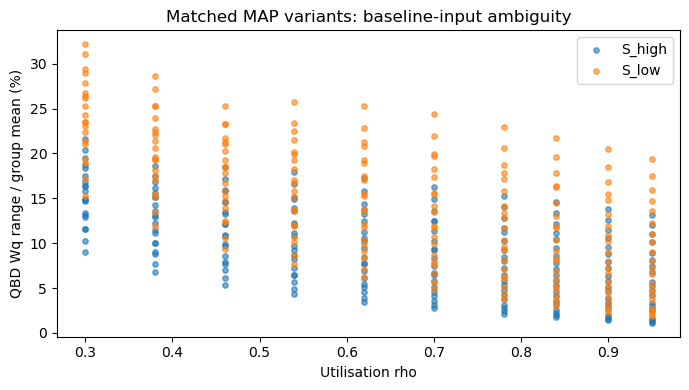

In [38]:
spread=labels.groupby(['region','group_id']).agg(rho=('rho','first'),SCV_A=('arrival_scv','first'),SCV_S=('service_scv','first'),
    min_QBD=('Wq_qbd','min'),max_QBD=('Wq_qbd','max'),mean_QBD=('Wq_qbd','mean'),
    min_r1=('lag1_corr','min'),max_r1=('lag1_corr','max')).reset_index()
spread['QBD_spread_pct']=100*(spread.max_QBD-spread.min_QBD)/spread.mean_QBD
spread.to_csv(OUTPUT/'matched_MAP_spread.csv',index=False)
print(spread.groupby('region').QBD_spread_pct.describe().round(3))
fig,ax=plt.subplots(figsize=(7,4))
for region,g in spread.groupby('region'):
    ax.scatter(g.rho,g.QBD_spread_pct,s=15,alpha=.6,label=region)
ax.set(xlabel='Utilisation rho',ylabel='QBD Wq range / group mean (%)',title='Matched MAP variants: baseline-input ambiguity')
ax.legend();fig.tight_layout();fig.savefig(OUTPUT/'matched_MAP_spread.png',dpi=150);plt.show()


## 11. Region-specific ML analyses: four methods × two feature sets

Hyperparameters are selected by **validation RMSE vs simulation labels** only. Then refit on train+validation, and evaluate each untouched test set once. Both feature sets use identical partition membership and identical tuning grids across regions. Full search may take time; use smoke first.


In [39]:
FEATURE_SETS={'baseline':['rho','arrival_scv','service_scv'],
              'dependence_aware':['rho','arrival_scv','service_scv','lag1_corr']}
CANDIDATES={
    'Linear Regression':[{}],
    'Decision Tree':[{'max_depth':d,'min_samples_leaf':l} for d in [3,5,None] for l in [1,2]],
    'Random Forest':[{'n_estimators':200,'max_depth':d,'min_samples_leaf':l} for d in [5,None] for l in [1,2]],
    'XGBoost':[{'n_estimators':n,'max_depth':d,'learning_rate':rate} for n in [150,300] for d in [2,3] for rate in [.03,.08]],
}

def make_model(name,params):
    if name=='Linear Regression':return LinearRegression(**params)
    if name=='Decision Tree':return DecisionTreeRegressor(random_state=BASE_SEED,**params)
    if name=='Random Forest':return RandomForestRegressor(random_state=BASE_SEED,n_jobs=-1,**params)
    if name=='XGBoost':return XGBRegressor(objective='reg:squarederror',random_state=BASE_SEED,n_jobs=1,verbosity=0,**params)
    raise ValueError(name)

def metrics(actual,pred):
    actual=np.asarray(actual);pred=np.asarray(pred)
    return {'MAE':float(mean_absolute_error(actual,pred)),
            'RMSE':float(np.sqrt(mean_squared_error(actual,pred))),
            'R2':float(r2_score(actual,pred)),
            'MAPE_pct':float(np.mean(100*np.abs(pred-actual)/np.maximum(np.abs(actual),1e-10))),
            'NRMSE_mean_pct':float(100*np.sqrt(mean_squared_error(actual,pred))/np.mean(actual))}



In [40]:
def fit_region(region,trainval,heldout,prefix):
    selection=[]; results=[]; predictions=[]; timing=[]
    train=trainval[trainval.split=='train']; val=trainval[trainval.split=='validation']
    dev=pd.concat([train,val],ignore_index=True)
    test=heldout
    assert set(dev.group_id).isdisjoint(set(test.group_id))
    assert set(train.group_id).isdisjoint(set(val.group_id))
    for fs,cols in FEATURE_SETS.items():
        for name,options in CANDIDATES.items():
            scores=[]
            for p in options:
                model=make_model(name,p)
                model.fit(train[cols],train.Wq_sim_mean)
                yhat=model.predict(val[cols])
                scores.append((float(np.sqrt(mean_squared_error(val.Wq_sim_mean,yhat))),p))
            err,pbest=min(scores,key=lambda a:a[0])
            selection.append(dict(region=region,features=fs,model=name,validation_RMSE=err,params=json.dumps(pbest)))
            model=make_model(name,pbest)
            t0=time.perf_counter();model.fit(dev[cols],dev.Wq_sim_mean);fit_time=time.perf_counter()-t0
            t0=time.perf_counter();pred=model.predict(test[cols]);prediction_time=time.perf_counter()-t0
            timing.append(dict(region=region,features=fs,model=name,fit_seconds=fit_time,prediction_seconds=prediction_time,n_test=len(test)))
            for target,reference in [(test.Wq_sim_mean,'simulation'),(test.Wq_qbd,'QBD')]:
                results.append(dict(region=region,features=fs,model=name,reference=reference,**metrics(target,pred)))
            for k,(cid,y) in enumerate(zip(test.config_id,pred)):
                predictions.append(dict(region=region,config_id=cid,features=fs,model=name,prediction=float(y)))
    return tuple(pd.DataFrame(x) for x in [selection,results,predictions,timing])

parts=[]
for region in SERVICE_GRIDS:
    part=labels[labels.region==region]
    parts.append(fit_region(region,part,part[part.split=='test'],region))
selection_df,results_df,prediction_df,timing_df=[pd.concat([p[i] for p in parts],ignore_index=True) for i in range(4)]
for name,df in [('regional_validation_search',selection_df),('regional_heldout_results',results_df),
                ('regional_heldout_predictions',prediction_df),('regional_model_timing',timing_df)]:
    df.to_csv(OUTPUT/(name+'.csv'),index=False)
print(results_df[results_df.reference=='QBD'].sort_values(['region','features','RMSE']).round(4).to_string(index=False))


region         features             model reference    MAE   RMSE     R2  MAPE_pct  NRMSE_mean_pct
S_high         baseline           XGBoost       QBD 0.2374 0.4444 0.9969    6.7552          6.6289
S_high         baseline     Random Forest       QBD 0.2674 0.5846 0.9946    4.3384          8.7199
S_high         baseline     Decision Tree       QBD 0.3408 0.6694 0.9929    5.6402          9.9849
S_high         baseline Linear Regression       QBD 3.8430 4.9976 0.6065  128.8473         74.5463
S_high dependence_aware           XGBoost       QBD 0.1677 0.4669 0.9966    2.9408          6.9648
S_high dependence_aware     Random Forest       QBD 0.2385 0.5250 0.9957    3.3694          7.8308
S_high dependence_aware     Decision Tree       QBD 0.3715 0.7481 0.9912    5.1112         11.1592
S_high dependence_aware Linear Regression       QBD 3.8348 4.9915 0.6075  128.8020         74.4541
 S_low         baseline           XGBoost       QBD 0.1660 0.2439 0.9981    6.4457          5.2221
 S_low    

## 12. Supplementary pooled analysis (optional common model)

Pooled training uses only the two regions' **train** rows, pooled validation uses only their **validation** rows, and final refit combines their development data. The original region-specific tests remain untouched. Report pooled test error separately **within each service region** rather than relying only on a global pooled score.

In [41]:
pooled_train=labels[labels.split=='train'];pooled_val=labels[labels.split=='validation']
pooled_dev=labels[labels.split!='test']; pooled_test=labels[labels.split=='test']
pooled_selection=[];pooled_results=[];pooled_predictions=[]
for fs,cols in FEATURE_SETS.items():
    for name,options in CANDIDATES.items():
        scores=[]
        for p in options:
            m=make_model(name,p);m.fit(pooled_train[cols],pooled_train.Wq_sim_mean)
            scores.append((float(np.sqrt(mean_squared_error(pooled_val.Wq_sim_mean,m.predict(pooled_val[cols])))),p))
        err,params=min(scores,key=lambda x:x[0]);pooled_selection.append(dict(features=fs,model=name,validation_RMSE=err,params=json.dumps(params)))
        m=make_model(name,params);m.fit(pooled_dev[cols],pooled_dev.Wq_sim_mean)
        for region in SERVICE_GRIDS:
            test=pooled_test[pooled_test.region==region];pred=m.predict(test[cols])
            for reference,truth in [('simulation',test.Wq_sim_mean),('QBD',test.Wq_qbd)]:
                pooled_results.append(dict(region=region,features=fs,model=name,reference=reference,**metrics(truth,pred)))
            for cid,y in zip(test.config_id,pred):
                pooled_predictions.append(dict(region=region,config_id=cid,features=fs,model=name,prediction=float(y)))
for nm,data in [('pooled_validation_search',pooled_selection),('pooled_heldout_by_region',pooled_results),('pooled_predictions',pooled_predictions)]:
    pd.DataFrame(data).to_csv(OUTPUT/(nm+'.csv'),index=False)
print(pd.DataFrame(pooled_results).query("reference=='QBD'").round(4).to_string(index=False))


region         features             model reference    MAE   RMSE     R2  MAPE_pct  NRMSE_mean_pct
 S_low         baseline Linear Regression       QBD 3.1272 3.6078 0.5783  198.2136         77.2398
S_high         baseline Linear Regression       QBD 3.5507 5.0587 0.5968   93.2992         75.4574
 S_low         baseline     Decision Tree       QBD 0.2990 0.4583 0.9932    8.0777          9.8109
S_high         baseline     Decision Tree       QBD 0.3408 0.6694 0.9929    5.6402          9.9849
 S_low         baseline     Random Forest       QBD 0.2075 0.3298 0.9965    6.3719          7.0618
S_high         baseline     Random Forest       QBD 0.2624 0.5903 0.9945    4.1232          8.8050
 S_low         baseline           XGBoost       QBD 0.1370 0.2180 0.9985    5.2998          4.6666
S_high         baseline           XGBoost       QBD 0.1976 0.4683 0.9965    3.1142          6.9851
 S_low dependence_aware Linear Regression       QBD 3.1281 3.6067 0.5785  198.6032         77.2161
S_high dep

## 13. Error diagnostics and controlled comparisons

Tables and figures compare all models and both feature sets across the same region-specific test splits. RMSE and MAE retain waiting-time units; `NRMSE_mean_pct` enables cautious cross-region comparisons. R² depends on each region's target variance. MAPE can be unstable near zero waiting time.

region         features             model  RMSE_separate  RMSE_pooled  RMSE_change_pooled_vs_separate_pct
 S_low         baseline Linear Regression          3.523        3.608                               2.415
 S_low         baseline     Decision Tree          0.458        0.458                              -0.000
 S_low         baseline     Random Forest          0.404        0.330                             -18.389
 S_low         baseline           XGBoost          0.244        0.218                             -10.638
 S_low dependence_aware Linear Regression          3.523        3.607                               2.382
 S_low dependence_aware     Decision Tree          0.338        0.383                              13.573
 S_low dependence_aware     Random Forest          0.336        0.326                              -2.928
 S_low dependence_aware           XGBoost          0.171        0.127                             -25.582
S_high         baseline Linear Regression     

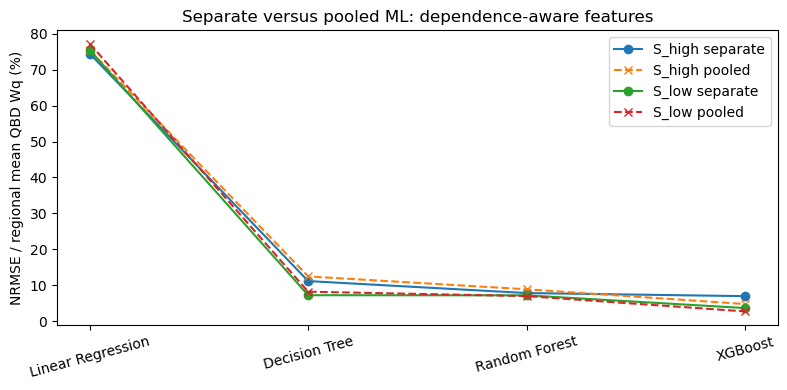

In [42]:
compare=results_df[results_df.reference=='QBD'].merge(
    pd.DataFrame(pooled_results).query("reference=='QBD'"),on=['region','features','model','reference'],suffixes=('_separate','_pooled'))
compare['RMSE_change_pooled_vs_separate_pct']=100*(compare.RMSE_pooled/compare.RMSE_separate-1)
compare.to_csv(OUTPUT/'separate_vs_pooled_comparison.csv',index=False)
print(compare[['region','features','model','RMSE_separate','RMSE_pooled','RMSE_change_pooled_vs_separate_pct']].round(3).to_string(index=False))
fig,ax=plt.subplots(figsize=(8,4))
for region,g in compare[compare.features=='dependence_aware'].groupby('region'):
    ax.plot(g.model,g.NRMSE_mean_pct_separate,marker='o',label=f'{region} separate')
    ax.plot(g.model,g.NRMSE_mean_pct_pooled,marker='x',linestyle='--',label=f'{region} pooled')
ax.set(ylabel='NRMSE / regional mean QBD Wq (%)',title='Separate versus pooled ML: dependence-aware features')
ax.tick_params(axis='x',rotation=15);ax.legend();fig.tight_layout();fig.savefig(OUTPUT/'separate_pooled_comparison.png',dpi=150);plt.show()

prediction_errors=prediction_df.merge(labels[['config_id','region','rho','arrival_scv','service_scv','lag1_corr','Wq_sim_mean','Wq_qbd','split']],
    on=['config_id','region'],validate='many_to_one')
assert (prediction_errors.split=='test').all()
prediction_errors['absolute_QBD_error']=(prediction_errors.prediction-prediction_errors.Wq_qbd).abs()
prediction_errors['relative_QBD_error_pct']=100*prediction_errors.absolute_QBD_error/prediction_errors.Wq_qbd
prediction_errors.to_csv(OUTPUT/'regional_test_pointwise_diagnostics.csv',index=False)


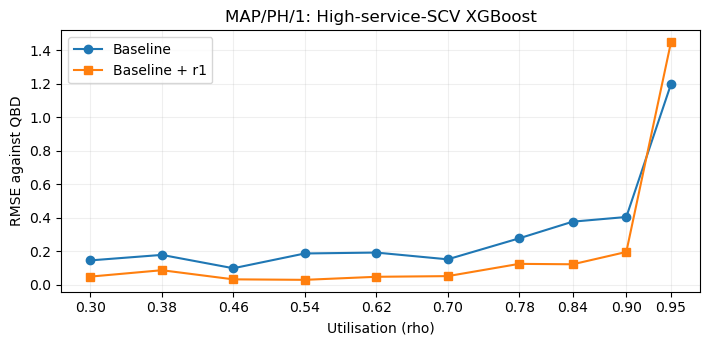

In [45]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(OUTPUT / "regional_test_pointwise_diagnostics.csv")

# Select high-service-SCV XGBoost results
df = df[
    (df["region"] == "S_high") &
    (df["model"] == "XGBoost")
]

# Calculate RMSE by utilisation and feature set
rmse = (
    df.groupby(["rho", "features"])
      .apply(
          lambda g: np.sqrt(
              np.mean((g["prediction"] - g["Wq_qbd"]) ** 2)
          ),
          include_groups=False
      )
      .unstack()
)

# Plot the results
fig, ax = plt.subplots(figsize=(7.2, 3.55))

ax.plot(rmse.index, rmse["baseline"],
        marker="o", label="Baseline")

ax.plot(rmse.index, rmse["dependence_aware"],
        marker="s", label="Baseline + r1")

ax.set_xlabel("Utilisation (rho)")
ax.set_ylabel("RMSE against QBD")
ax.set_title("MAP/PH/1: High-service-SCV XGBoost")
ax.set_xticks(rmse.index)
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(OUTPUT / "MAP_PH1_XGBoost_RMSE_by_rho.png", dpi=230)
plt.show()
